Problema de import? Rodar:
!pip install nome_lib

!pip install kagglehub

In [1]:
import kagglehub
import pandas as pd
import os
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [2]:
path = kagglehub.dataset_download(
    "alexteboul/diabetes-health-indicators-dataset"
)
csv_path = os.path.join(path, "diabetes_012_health_indicators_BRFSS2015.csv")
df = pd.read_csv(csv_path)

In [3]:
print(df.head())
print(df.shape)
print(df.info())
df.isnull().sum()

   Diabetes_012  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0           0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1           0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2           0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3           0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4           0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.0  0.0   9.0        4.0   
1     

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

<Axes: >

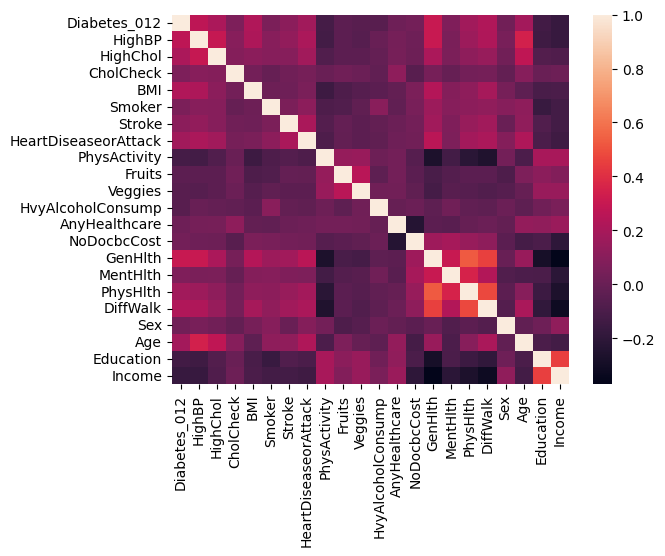

In [4]:
correlacao = df.corr()
sns.heatmap(correlacao)

Retirada apenas da coluna Diabetes_012, pois contém os rótulos de diabetes.
Outras colunas não demonstram correlação grande o suficiente para haver redundância
Problema: É possível identificar diferentes perfis de estilo de vida e saúde na população a partir de hábitos como tabagismo, alimentação e atividade física?


In [5]:
variaveis = [
    "Smoker",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "BMI",
    "GenHlth",
    "PhysHlth",
    "MentHlth",
    "HighBP",
    "HighChol",
    "Age",
    "Income",
    "Education"
]

X = df[variaveis]

In [6]:
y = df["Diabetes_012"]

In [7]:
#PCA
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
pca = PCA()

pca.fit(X_scaled)

PCA()

In [8]:
explained = np.cumsum(
    pca.explained_variance_ratio_
)

print(explained)

[0.20654731 0.31065668 0.39834799 0.47888785 0.55674767 0.62289405
 0.68324823 0.74310445 0.79549499 0.84614306 0.89232835 0.9319907
 0.96934468 1.        ]


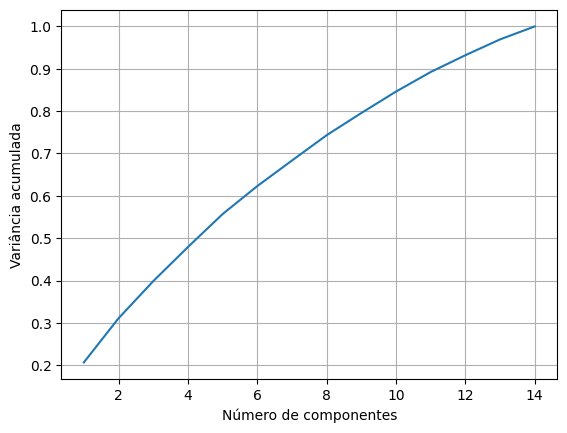

In [9]:
plt.plot(
    range(1, len(explained)+1),
    explained
)

plt.xlabel("Número de componentes")
plt.ylabel("Variância acumulada")
plt.grid()
plt.show()

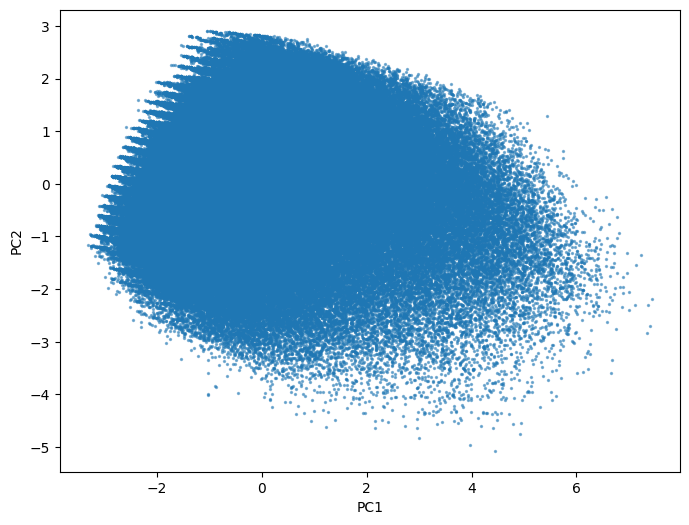

In [10]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8,6))

plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    s=2,
    alpha=0.5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [11]:
#INICIANDO K-MEANS

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

In [12]:
resultados = []

for k in range(2, 3):

    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    davies = davies_bouldin_score(X_scaled, labels)
    calinski = calinski_harabasz_score(X_scaled, labels)

    resultados.append({
        "k": k,
        "silhouette": silhouette,
        "davies_bouldin": davies,
        "calinski_harabasz": calinski
    })


for r in resultados:
    print(r)

{'k': 2, 'silhouette': np.float64(0.1723739582324043), 'davies_bouldin': np.float64(2.40051081647996), 'calinski_harabasz': np.float64(40320.07697815031)}


In [ ]:
resultados2 = []

for k in range(3, 10):

    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    davies = davies_bouldin_score(X_scaled, labels)
    calinski = calinski_harabasz_score(X_scaled, labels)

    resultados.append({
        "k": k,
        "silhouette": silhouette,
        "davies_bouldin": davies,
        "calinski_harabasz": calinski
    })


for r in resultados2:
    print(r)